# Solution notebook

The student workbook with every task function implemented; for tutors.

# Lab 2 — Student workbook: predicting with ECG, from features to foundation models

## 0. Setup

**Runtime.** *Runtime > Change runtime type > T4 GPU*; about ten minutes on the free T4.

In [1]:
!pip install -q numpy matplotlib "neurokit2>=0.2.13" scikit-learn torch tqdm huggingface_hub pandas

/bin/bash: line 1: pip: command not found


### import relevant packages

In [2]:
# Import Python basic libraries
import numpy as np
import matplotlib.pyplot as plt
import pickle as pk
import neurokit2 as nk
import tqdm

# Plot configurations
%config InlineBackend.figure_formats = {'png', 'retina'}
plt.rcParams['axes.labelsize'] = 16  # fontsize for figure labels
plt.rcParams['axes.titlesize'] = 18  # fontsize for figure titles


This cell prepares the data and helper code for this lab. The cell will ask a password, which will be distributed in class. If you have any question, **ask the tutor**. 

In [3]:
KIT_REPO = 'https://github.com/junjiechen-chris/CDT-ECG-Lab2'                    # the lab's code
DATA_ZIP_URL = 'https://huggingface.co/datasets/junjiechen-chris/CDT-HDS-ECG-Lab-2-data/resolve/main/ECG_lab2_data.zip'

import os, sys
KIT_DIR = os.environ.get('LAB2_KIT', 'kit/code')
if not os.path.exists(os.path.join(KIT_DIR, 'frontier_kit.py')):
    !git clone -q $KIT_REPO kit
sys.path.insert(0, KIT_DIR)

FILES = ['ECG.pkl', 'ECG_feature.pkl', 'alivecor_hidden.pkl', 'ptbxl_af.pkl', 'sex.pkl', 'apnea.pkl']
os.makedirs('data', exist_ok=True)
if any(not os.path.exists(f'data/{f}') for f in FILES):      # a password-protected zip; the password is given in the lab
    import getpass
    from urllib.request import urlretrieve
    if not os.path.exists('data/ECG_lab2_data.zip'):
        print('downloading the data zip (431 MB) ...'); urlretrieve(DATA_ZIP_URL, 'data/ECG_lab2_data.zip')
    password = getpass.getpass('Password for the data zip: ')
    !unzip -q -o -P "$password" data/ECG_lab2_data.zip -d data

import torch
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using', torch.cuda.get_device_name(0) if device == 'cuda' else 'the CPU (slower; Runtime > Change runtime type > T4 GPU)')
import lab2_checks as checks

Using NVIDIA RTX A6000


## 1. Preparing the three tasks
 

### The three tasks and the benchmark

| Task | Train | Validation | Hidden test | Metric |
|---|---|---|---|---|
| **AF**: N, A, O, ~, per recording | 1,500 PhysioNet 2017 recordings | 500 | 6,528 other PhysioNet 2017 recordings | macro F1 |
| **Sex**: female or male, per 10 s recording | 3,258 PTB-XL ECGs | 1,123 | 1,000 Chapman–Shaoxing ECGs | AUROC |
| **Apnea**: yes or no, per minute | 5,676 Apnea-ECG minutes | 1,939 | 3,471 UCD St Vincent's minutes | AUROC |



In [4]:
from frontier_kit import CLASSES, alivecor_split, write_submission, check_submission
from systems import Data, tasks, to_files

D = Data('data')          # the recordings above, the four packs, and the AF split
import frontier_kit; frontier_kit._cache.update(alivecor_hidden=D.hid, ptbxl_af=D.ptb, sex=D.sex, apnea=D.apn)   # load each pack once
T = tasks(D)              # per task: raw signals, Lab 1 features, labels, train / validation indices, hidden targets
for name, t in T.items():
    print(f"{name:9s} train {len(t['tr']):5d}   validation {len(t['va']):5d}   hidden: "
          + ', '.join(f'{k} {len(v["raw"])}' for k, v in t['targets'].items()))

def split_by_person(person, val_frac=0.25, seed=0):
    people = np.unique(person)
    val_people = np.random.default_rng(seed).choice(people, int(round(val_frac * len(people))), replace=False)
    return np.where(~np.isin(person, val_people))[0], np.where(np.isin(person, val_people))[0]

def geomean(scores):
    return float(np.exp(np.mean(np.log(scores))))

tr, va = split_by_person(D.apn['apnea_ecg_person'])
assert set(va) == set(D.apn['val'])
print(len(np.unique(D.apn['apnea_ecg_person'])), 'people;', len(np.unique(D.apn['apnea_ecg_person'][va])), 'in validation')

alivecor  train  1500   validation   500   hidden: alivecor 6528, ptbxl_af 4381
sex       train  3258   validation  1123   hidden: sex 1000
apnea     train  5676   validation  1939   hidden: apnea 3471
70 people; 18 in validation


### Random Forest: Lab 1 classifier


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from systems import macro_f1, auroc
import pandas as pd

score = {'alivecor': macro_f1, 'sex': auroc, 'apnea': auroc}
val, preds = {}, {}

def score_table():
    table = pd.DataFrame(val).T[['alivecor', 'sex', 'apnea']].rename(columns={'alivecor': 'AF (macro F1)', 'sex': 'Sex (AUROC)', 'apnea': 'Apnea (AUROC)'})
    table['geomean'] = [geomean(row) for row in table.values]
    return table.round(3)

val['RF'], preds['RF'] = {}, {}
for name, t in T.items():
    scaler = StandardScaler().fit(t['F'][t['tr']])
    model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(scaler.transform(t['F'][t['tr']]), t['y'][t['tr']])
    val['RF'][name] = score[name](t['y'][t['va']], model.predict_proba(scaler.transform(t['F'][t['va']])))
    print(f"RF, {name}: validation {val['RF'][name]:.3f}")
    for file, target in t['targets'].items():
        preds['RF'][file] = model.predict_proba(scaler.transform(target['F']))
score_table()

RF, alivecor: validation 0.619


RF, sex: validation 0.684


RF, apnea: validation 0.900


,AF (macro F1),Sex (AUROC),Apnea (AUROC),geomean
RF,0.619,0.684,0.9,0.725


## 2. End-to-end classification: ResNet 

In [6]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from model import resnet1d18

label_mapping = {c: i for i, c in enumerate(CLASSES)}   # N, A, O, ~ -> 0, 1, 2, 3, the order of every label array

### 2.1 Data preparation

We clean every recording with `nk.ecg_clean`, and cut it to a fixed length with `crop` so that neural networks can work in batch.

### Task 2A Write `crop`

Write `crop`. `x` is a cleaned ECG recording, a float array of shape `(T,)`, where $T$ differs per recording (9 to 61 s at 300 Hz); `length` is the expected window size (3,000 samples for 10 s); `train` is a flag to indicate which type of cropping we will perform.

1. If $T \le$ `length`: pad `x` with zeros at the end to `(length,)` and return it.
2. Otherwise choose the window start:
   - `train=True`: `start` drawn uniformly from 0 to `len(x) - length` with `np.random.randint`;
   - `train=False`: `start = 0`.
3. Return `x[start:start + length]`, shape `(length,)`.

**Specification: `crop(x, length, train)`**
- **Given:** `x`, a float array of shape `(T,)`; `length`, an int; `train`, a bool.
- **You may use:** `np.random.randint`, `np.pad`.
- **Return:** a float array of shape `(length,)`.
- **Tested by:** fixed signals (long, short, exactly `length`), and 30 random training windows.

In [7]:
def crop(x, length, train):
    if len(x) > length:
        start = np.random.randint(0, len(x) - length + 1) if train else 0
        return x[start:start + length]
    return np.pad(x, (0, length - len(x)), 'constant')

In [8]:
crop = checks.check_crop(crop)

crop: check passed. The notebook uses your function from here on.


`make_batch` stacks the cropped windows of a batch into one tensor.

In [9]:
def clean(signals):
    return [nk.ecg_clean(np.asarray(s, dtype=float) / 1000.0, sampling_rate=300).astype(np.float32) for s in signals]

def make_batch(signals, length, train):
    windows = [crop(np.asarray(s, dtype=np.float32), length, train) for s in signals]
    windows = np.stack(windows)
    return torch.from_numpy(windows[:, None, :]).to(device)

clean_af = clean(T['alivecor']['raw'])      
print(make_batch(clean_af[:4], 3000, train=True).shape)

torch.Size([4, 1, 3000])


### 2.2 ResNet18 

`build_model` setup the network (`resnet1d18`), its optimiser (Adam) and its loss (cross-entropy).

In [10]:
def build_model(n_classes, lr=1e-3):
    torch.manual_seed(0)
    np.random.seed(0)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    model = resnet1d18(num_classes=n_classes, input_channels=1).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    return model, optimizer, criterion

ecg_model, optimizer, criterion = build_model(n_classes=4)
print(sum(p.numel() for p in ecg_model.parameters()), 'coefficients')

3845956 coefficients


### 2.3 Prediction

### Task 2B Write `predict_proba`

Write `predict_proba`. `signals` is a list of ECG recordings, float arrays of shape `(T_i,)` where $T_i$ may differ per recording; `model` is a `resnet1d18` on `device`; `length` is the window size that the model reads.

1. Put the model in evaluation mode and run under `torch.no_grad()`.
2. Iterate over the signals in batches. For each batch:
   - `make_batch(batch, length, train=False)` gives a float tensor `(bs, 1, length)`;
   - `model(x)` maps it to scores `(bs, n_classes)`;
   - `torch.softmax` over axis 1 gives probabilities `(bs, n_classes)`; move them to NumPy.
3. Concatenate the batches along axis 0 to `(n, n_classes)`.

**Specification: `predict_proba(model, signals, length, batch_size=256)`**
- **Given:** `model`, a `resnet1d18` on `device`; `signals`, a list of `n` float arrays of shape `(T_i,)`; `length`, an int; `batch_size`, an int.
- **You may use:** `make_batch` (2.1), `model.eval()`, `torch.no_grad()`, `torch.softmax`, `np.concatenate`.
- **Return:** a float array of shape `(n, n_classes)`, class probabilities.

In [11]:
def predict_proba(model, signals, length, batch_size=256):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(signals), batch_size):
            scores = model(make_batch(signals[i:i + batch_size], length, train=False))
            out.append(torch.softmax(scores, 1).cpu().numpy())
    return np.concatenate(out)

In [12]:
predict_proba = checks.check_predict_proba(predict_proba)

predict_proba: check passed. The notebook uses your function from here on.


### 2.4 Train ResNet18

In [13]:
def train_resnet_classifier(signals, labels, train_idx, val_idx, n_classes,
                            length=None, epochs=20, batch_size=128):
    labels = np.asarray(labels)
    length = length or max(len(s) for s in signals)
    score = macro_f1 if n_classes > 2 else auroc
    model, optimizer, criterion = build_model(n_classes)
    predict = lambda sigs: predict_proba(model, sigs, length)  # noqa: E731

    best_score, best_state = -1.0, None
    rng = np.random.default_rng(0)
    for epoch in range(epochs):
        model.train()
        order = rng.permutation(train_idx)
        for i in range(0, len(order), batch_size):
            batch_idx = order[i:i + batch_size]
            optimizer.zero_grad()
            batch = make_batch([signals[j] for j in batch_idx], length, train=True)
            targets = torch.from_numpy(labels[batch_idx]).long().to(device)
            loss = criterion(model(batch), targets)
            loss.backward()
            optimizer.step()
        val_score = score(labels[val_idx], predict([signals[j] for j in val_idx]))
        print(f'epoch {epoch + 1}/{epochs}: validation {val_score:.3f}', flush=True)
        if val_score > best_score:
            best_score = val_score
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, predict, best_score

Here we train our ResNet model on the AF task.

In [14]:
SETTINGS = {'alivecor': dict(epochs=20, batch_size=128, length=3000),   # 10 s windows
            'sex':      dict(epochs=3,  batch_size=128, length=3000),
            'apnea':    dict(epochs=2,  batch_size=32,  length=None)}   # whole 1-minute windows

from sklearn.metrics import classification_report

af = T['alivecor']
val['ResNet'], preds['ResNet'] = {}, {}
ecg_model, predict_af, val['ResNet']['alivecor'] = train_resnet_classifier(
    clean_af, af['y'], af['tr'], af['va'], af['n'], **SETTINGS['alivecor'])

val_pred = predict_af([clean_af[j] for j in af['va']]).argmax(1)
print(classification_report(af['y'][af['va']], val_pred, target_names=CLASSES))
print(f"ResNet, AF: validation macro F1 {val['ResNet']['alivecor']:.3f}   (RF: {val['RF']['alivecor']:.3f})")
for file, target in af['targets'].items():
    preds['ResNet'][file] = predict_af(clean(target['raw']))

epoch 1/20: validation 0.186


epoch 2/20: validation 0.187


epoch 3/20: validation 0.186


epoch 4/20: validation 0.280


epoch 5/20: validation 0.248


epoch 6/20: validation 0.399


... (11 outputs left out)

epoch 18/20: validation 0.478


epoch 19/20: validation 0.516


epoch 20/20: validation 0.555


              precision    recall  f1-score   support

           N       0.80      0.74      0.77       297
           A       0.54      0.43      0.48        49
           O       0.52      0.55      0.53       138
           ~       0.33      0.81      0.47        16

    accuracy                           0.66       500
   macro avg       0.55      0.63      0.56       500
weighted avg       0.68      0.66      0.67       500

ResNet, AF: validation macro F1 0.564   (RF: 0.619)


Here we further train two new ResNet models on the sex and apnea task.

In [15]:
for name in ['sex', 'apnea']:
    task, settings = T[name], SETTINGS[name]
    print(f'ResNet, {name}: {settings}')
    _, predict, val['ResNet'][name] = train_resnet_classifier(
        clean(task['raw']), task['y'], task['tr'], task['va'], task['n'], **settings)
    for file, target in task['targets'].items():
        preds['ResNet'][file] = predict(clean(target['raw']))
score_table()

ResNet, sex: {'epochs': 3, 'batch_size': 128, 'length': 3000}


epoch 1/3: validation 0.481


epoch 2/3: validation 0.575


epoch 3/3: validation 0.668


ResNet, apnea: {'epochs': 2, 'batch_size': 32, 'length': None}


epoch 1/2: validation 0.654


epoch 2/2: validation 0.773


,AF (macro F1),Sex (AUROC),Apnea (AUROC),geomean
RF,0.619,0.684,0.900,0.725
ResNet,0.564,0.668,0.773,0.663


## 3. Foundation model classification: ECGFounder

We use ECGFounder as a feature extractor like the neurokit2. Except that neurokit's feature is interpretable, and ECGFounder's is not. 

In [16]:
from ecgfounder import load_model

fm_model = load_model(device)

`preprocess_for_ecgfounder_batch` converts raw 300 Hz signals to the format ECGFounder was trained on: `(n, 1, 5000)` float32 at 500 Hz. The pipeline: crop/pad to 10 s → resample 300 → 500 Hz → 50 Hz notch → 0.67–40 Hz bandpass → median baseline removal → z-score.

In [17]:
from scipy.signal import resample_poly, iirnotch, filtfilt, butter, medfilt

FS_IN, FS_FM, SECONDS = 300, 500, 10
N_FM = FS_FM * SECONDS  # 5000

def preprocess_for_ecgfounder_batch(sigs):
    """Raw 300 Hz signals (µV) → (n, 1, 5000) float32 at 500 Hz, filtered and z-scored."""
    n_in = FS_IN * SECONDS                # 3000 samples = 10 s at 300 Hz
    lens = [min(len(s), n_in) for s in sigs]
    x = np.stack([np.pad(np.asarray(s, dtype=float)[:n_in], (0, n_in - n)) for s, n in zip(sigs, lens)]) / 1000.0
    x = resample_poly(x, 5, 3, axis=1)[:, :N_FM]          # 300 → 500 Hz
    for i, n in enumerate(lens):
        x[i, int(np.ceil(n * 5 / 3)):] = 0.0              # zero-fill short tails
    b, a = iirnotch(50, 30, FS_FM)
    x = filtfilt(b, a, x, axis=1)                          # 50 Hz notch
    b, a = butter(N=4, Wn=[0.67, 40], btype='bandpass', fs=FS_FM)
    x = filtfilt(b, a, x, axis=1)                          # 0.67–40 Hz bandpass
    k = int(0.4 * FS_FM) + 1; k += 1 - k % 2
    x = x - np.stack([medfilt(c, kernel_size=k) for c in x])  # baseline removal
    x = (x - x.mean(1, keepdims=True)) / (x.std(1, keepdims=True) + 1e-8)  # z-score
    return x[:, None, :].astype(np.float32)

raw: (9000,) at 300 Hz  →  processed: (1, 1, 5000) at 500 Hz


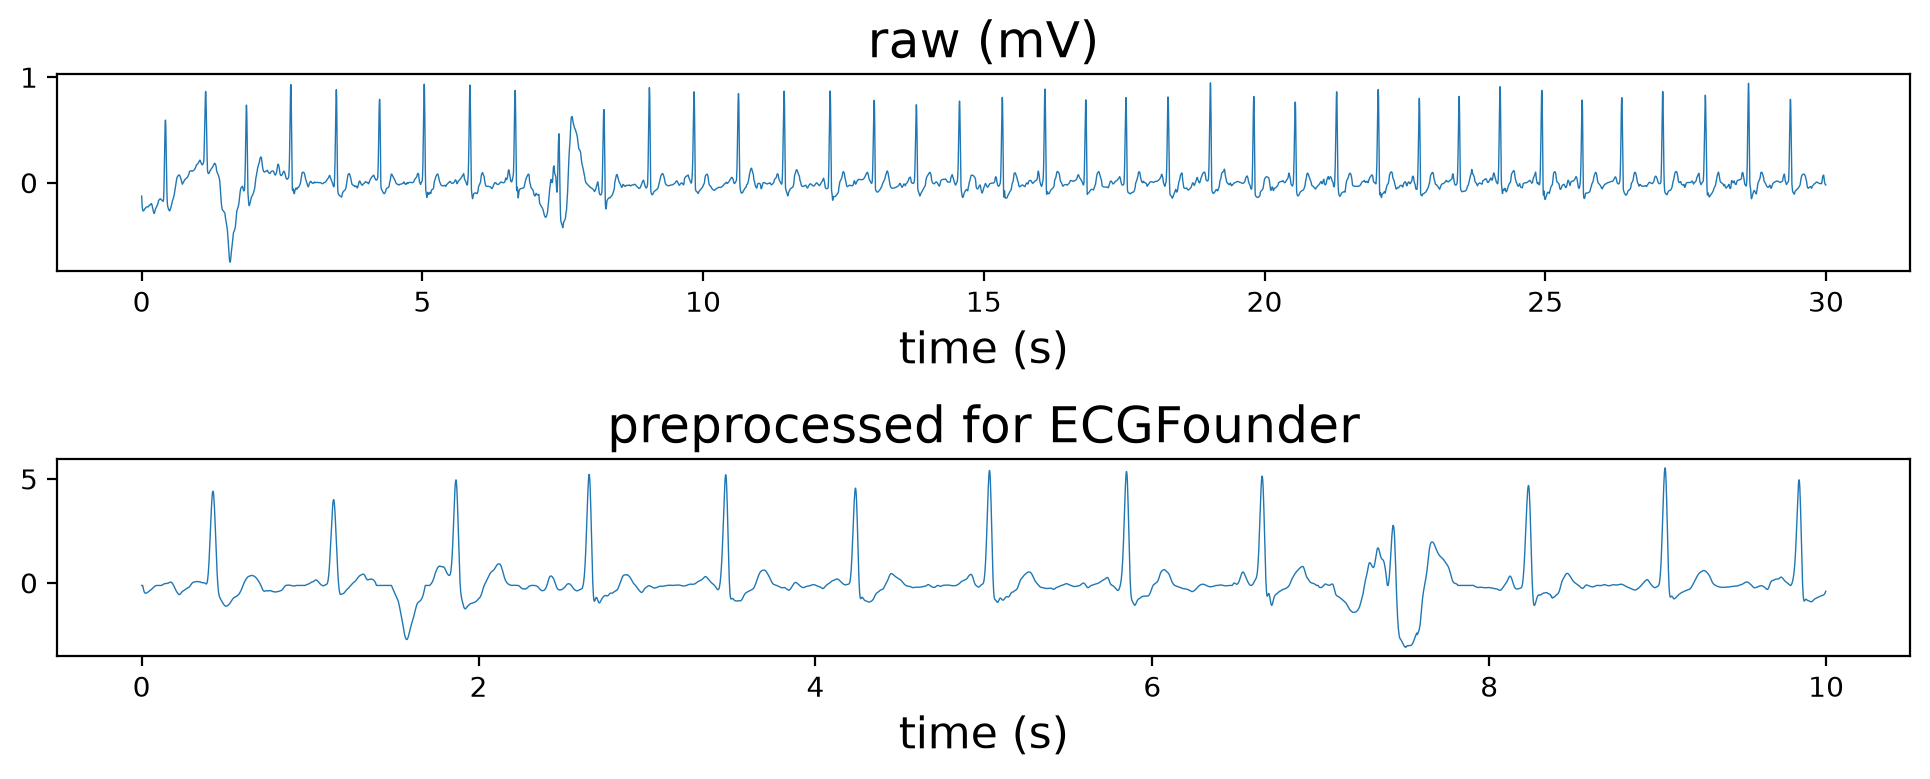

In [18]:
raw_example = D.raw_af[0]
processed = preprocess_for_ecgfounder_batch([raw_example])
print(f'raw: ({len(raw_example)},) at 300 Hz  →  processed: {processed.shape} at 500 Hz')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 4))
ax1.plot(np.arange(len(raw_example)) / 300, np.asarray(raw_example) / 1000, lw=0.5)
ax1.set(title='raw (mV)', xlabel='time (s)')
ax2.plot(np.arange(5000) / 500, processed[0, 0], lw=0.5)
ax2.set(title='preprocessed for ECGFounder', xlabel='time (s)')
plt.tight_layout()

In [19]:
def embed(model, raw, bs=256):
    E = []
    with torch.no_grad():
        for i in range(0, len(raw), bs):
            X = preprocess_for_ecgfounder_batch(raw[i:i + bs])
            logits, features = model(torch.from_numpy(X).to(device))
            E.append(features.cpu().numpy())
    return np.concatenate(E)

E_af = embed(fm_model, D.raw_af)
print(E_af.shape)

(2000, 1024)


### 3.1 A linear classifier on the frozen embeddings, for the three tasks

### Task 3A Write `pool_windows`

Write `pool_windows`. `E` holds the window embeddings, shape `(n * windows, d)`; recording `i` occupies rows `i*windows` to `(i+1)*windows - 1`.

1. Reshape `E` to `(n, windows, d)`.
2. Take the mean and the standard deviation (`ddof=0`) over axis 1, each `(n, d)`.
3. Concatenate them along axis 1, mean first: row `i` is `[mean_i, std_i]`, so the result is `(n, 2d)`.

**Specification: `pool_windows(E, windows)`**
- **Given:** `E`, a float array of shape `(n * windows, d)`; `windows`, an int.
- **You may use:** `np.reshape`, `np.mean`, `np.std`, `np.concatenate`.
- **Return:** a float array of shape `(n, 2d)`.
- **Tested by:** a reference on a fixed random array.

In [20]:
def pool_windows(E, windows):
    E = np.asarray(E).reshape(len(E) // windows, windows, -1)
    return np.concatenate([E.mean(axis=1), E.std(axis=1)], axis=1)

In [21]:
pool_windows = checks.check_pool_windows(pool_windows)

pool_windows: check passed. The notebook uses your function from here on.


### Task 3B Write `linear_classifier`

Write `linear_classifier`. `E_train` holds the embeddings of the training signals, shape `(n_train, d)`; `y_train` their labels, shape `(n_train,)`; `E_eval` the embeddings of the signals to predict, shape `(n_eval, d)`.

1. Fit a `StandardScaler` on `E_train` only; transform `E_train` and `E_eval` with it.
2. Fit `LogisticRegression(C=0.01, max_iter=3000)` on the standardised `E_train` and `y_train`.
3. Return `predict_proba` of the standardised `E_eval`, shape `(n_eval, n_classes)`.

**Specification: `linear_classifier(E_train, y_train, E_eval)`**
- **Given:** `E_train`, a float array of shape `(n_train, d)`; `y_train`, an int array of shape `(n_train,)`; `E_eval`, a float array of shape `(n_eval, d)`.
- **You may use:** `StandardScaler` and `LogisticRegression` from scikit-learn.
- **Return:** a float array of shape `(n_eval, n_classes)`, class probabilities.
- **Tested by:** a reference on fixed random data; then its validation score on the three tasks.

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

def linear_classifier(E_train, y_train, E_eval):
    scaler = StandardScaler().fit(E_train)
    model = LogisticRegression(C=0.01, max_iter=3000).fit(scaler.transform(E_train), y_train)
    return model.predict_proba(scaler.transform(E_eval))

In [23]:
linear_classifier = checks.check_linear_classifier(linear_classifier)

linear_classifier: check passed. The notebook uses your function from here on.


In [24]:
def embed_task(raw, windows=1):
    if windows == 1:
        return embed(fm_model, raw)
    pieces = [p for s in raw for p in np.split(np.asarray(s, float), windows)]
    return pool_windows(embed(fm_model, pieces), windows)

val['ECGFounder'], preds['ECGFounder'] = {}, {}
for name, windows in [('alivecor', 1), ('sex', 1), ('apnea', 6)]:
    t = T[name]
    E = E_af if name == 'alivecor' else embed_task(t['raw'], windows)
    val['ECGFounder'][name] = score[name](t['y'][t['va']], linear_classifier(E[t['tr']], t['y'][t['tr']], E[t['va']]))
    print(f"ECGFounder + linear classifier, {name}: validation {val['ECGFounder'][name]:.3f}")
    for file, target in t['targets'].items():
        preds['ECGFounder'][file] = linear_classifier(E[t['tr']], t['y'][t['tr']], embed_task(target['raw'], windows))
score_table()

ECGFounder + linear classifier, alivecor: validation 0.636


ECGFounder + linear classifier, sex: validation 0.699


ECGFounder + linear classifier, apnea: validation 0.932


,AF (macro F1),Sex (AUROC),Apnea (AUROC),geomean
RF,0.619,0.684,0.900,0.725
ResNet,0.564,0.668,0.773,0.663
ECGFounder,0.636,0.699,0.932,0.745


## 4. Beating the baselines

### Task 4 Beat the baselines

Time to put everything together. Write train and predict; the stubs below set up a RandomForest. Change whatever you like, and beat the baselines.

Below are a few ideas to improve on our RandomForest, ResNet and ECGFounder systems. Everything defined above is available: `embed_task`, `linear_classifier`, `train_resnet_classifier`, `clean`, `E_af`.
- **model ensembling**: average the probabilities of two systems;
- **feature engineering**: give a classifier the 54 features *and* the embedding together;
- **model selection**: another classifier on the embedding, or other settings (`C`, number of trees);
- **hyperparameter tuning**: more epochs, another learning rate, another crop length for the ResNet (`SETTINGS` in 2.4);
- **fine-tuning the foundation model**: replace `fm_model.dense` with a new head and train it end to end on our labels.

In [25]:
from ecgfounder import ECGFounderClassifier, preprocess_many

FT = {'alivecor': dict(windows=1, epochs=12, bs=32), 'sex': dict(windows=1, epochs=6, bs=32), 'apnea': dict(windows=6, epochs=4, bs=8)}


def prepare(raw, windows, n=3000):
    if windows > 1:
        X = np.concatenate([preprocess_many(list(raw[i:i + 512]), windows=windows) for i in range(0, len(raw), 512)])
        return X, np.arange(len(raw))
    wins = [[np.pad(s, (0, n - len(s)))] if len(s) < n else [s[i * n:(i + 1) * n] for i in range(len(s) // n)]
            for s in (np.asarray(r, float) for r in raw)]
    owner = np.repeat(np.arange(len(raw)), [len(w) for w in wins])
    flat = [w for ws in wins for w in ws]
    return np.concatenate([preprocess_many(flat[i:i + 2048]) for i in range(0, len(flat), 2048)]), owner


def predict(model, X, owner, bs=64):
    model.eval()
    out = []
    with torch.no_grad(), torch.autocast(device, enabled=device == 'cuda'):
        for i in range(0, len(X), bs):
            out.append(torch.softmax(model(torch.from_numpy(X[i:i + bs]).to(device)).float(), 1).cpu().numpy())
    p, n = np.concatenate(out), owner.max() + 1
    s = np.zeros((n, p.shape[1]))
    np.add.at(s, owner, p)
    return s / np.bincount(owner, minlength=n)[:, None]


def train(X, owner, y, tr, va, n_classes, metric, windows=1, epochs=8, bs=32, lr_backbone=3e-5, lr_head=1e-3,
          weight_decay=0.1, seed=0):
    """
    Our best model with
    - separate learning rate: backbone use 3e-5, linear classifier head 1e-3, with LR scheduling
    - reweigh the loss to compensate for the class imbalance in the dataset
    """
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    model = ECGFounderClassifier(n_classes, windows, device)
    opt = optim.AdamW([{'params': model.net.parameters(), 'lr': lr_backbone},
                       {'params': model.head.parameters(), 'lr': lr_head}], weight_decay=weight_decay)
    steps = epochs * int(np.ceil(len(tr) / bs))
    sched = optim.lr_scheduler.OneCycleLR(opt, max_lr=[lr_backbone, lr_head], total_steps=steps, pct_start=0.2)
    weight = torch.tensor(len(tr) / (n_classes * np.bincount(y[tr], minlength=n_classes)), dtype=torch.float32).to(device)
    criterion = nn.CrossEntropyLoss(weight=weight)
    scaler = torch.amp.GradScaler(enabled=device == 'cuda')
    rows_of = [np.flatnonzero(owner == i) for i in range(owner.max() + 1)]
    va_rows = np.isin(owner, va)
    pos = np.full(owner.max() + 1, -1)
    pos[va] = np.arange(len(va))
    best = (-1.0, None)
    for epoch in range(epochs):
        model.train()
        pick = np.array([rng.choice(rows_of[i]) for i in tr])
        order = rng.permutation(len(tr))
        for i in range(0, len(tr), bs):
            j = order[i:i + bs]
            opt.zero_grad()
            with torch.autocast(device, enabled=device == 'cuda'):
                loss = criterion(model(torch.from_numpy(X[pick[j]]).to(device)), torch.from_numpy(y[tr][j]).long().to(device))
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
        s = metric(y[va], predict(model, X[va_rows], pos[owner[va_rows]], bs))
        print(f'  epoch {epoch + 1}/{epochs}: validation {s:.3f}', flush=True)
        if s > best[0]:
            best = (s, copy.deepcopy(model.state_dict()))
    model.load_state_dict(best[1])
    return model, best[0]


val['mine'], test_predictions = {}, {}
for name in ['alivecor', 'sex', 'apnea']:
    t, st = T[name], FT[name]
    X, owner = prepare(t['raw'], st['windows'])
    model, val['mine'][name] = train(X, owner, t['y'], t['tr'], t['va'], t['n'], score[name], **st)
    print(f"mine, {name}: validation {val['mine'][name]:.3f}")
    for file, target in t['targets'].items():
        test_predictions[file] = predict(model, *prepare(target['raw'], st['windows']), bs=st['bs'])
    del model, X
    torch.cuda.empty_cache()


  epoch 1/12: validation 0.489


  epoch 2/12: validation 0.714


  epoch 3/12: validation 0.712


  epoch 4/12: validation 0.735


  epoch 5/12: validation 0.743


  epoch 6/12: validation 0.788


... (16 outputs left out)

  epoch 2/4: validation 0.959


  epoch 3/4: validation 0.966


  epoch 4/4: validation 0.964


mine, apnea: validation 0.966


In [26]:
score_table()

,AF (macro F1),Sex (AUROC),Apnea (AUROC),geomean
RF,0.619,0.684,0.900,0.725
ResNet,0.564,0.668,0.773,0.663
ECGFounder,0.636,0.699,0.932,0.745
mine,0.788,0.736,0.966,0.824


Put your name below. `write_submission` writes your predictions on the three test sets as `alivecor.csv`, `sex.csv` and `apnea.csv` and zips them with your note; `check_submission` checks the zip. Upload it on the leaderboard page; every upload is kept, so submit often.

In [27]:
TEAM = '<YOUR NAME>'   # appears on the leaderboard
NOTE = """
<YOUR NOTE>
"""

z = write_submission(f'{TEAM}-submission', author=TEAM, notes=NOTE, **to_files(test_predictions))
check_submission(z)

wrote submissions/<YOUR NAME>-submission/ and submissions/<YOUR NAME>-submission.zip
alivecor  ok (6528 rows)
ptbxl_af  ok (4381 rows)
sex       ok (1000 rows)
apnea     ok (3471 rows)
ready to upload


True

## Submit your work
- This notebook with task function implemented 
- Test-set submission package, with your note attached. 